# Deploy open-weight model on SageMaker endpoint using AWS Python API (boto3)

In this notebook, we will show how to deploy the `Qwen/Qwen3.5-4B` model on a SageMaker AI endpoint. 

## SageMaker inference benchmarking with speculative decoding

This notebook evaluates the effect of speculative decoding on model inference performance. The workflow is:

- Deploy the model **without speculative decoding** to the endpoint as Inference Component
- Deploy the model **with speculative decoding** to the endpoint as another Inference Component
- Run the benchmarks for both Inference Components and compare the performance of both configurations.

## Setup

The first cells prepare the notebook: they install the latest boto3, create the SageMaker AI clients, define small helper functions, and look up the IAM execution role that SageMaker AI uses to pull the container image and the model.

In [ ]:
%pip install --upgrade --quiet --no-warn-conflicts boto3

In [3]:
import time
import re
import json
import boto3
from IPython.display import display, Markdown, clear_output

boto_session = boto3.Session()
region = boto_session.region_name
account_id = boto3.client("sts").get_caller_identity()["Account"]

sm = boto3.client("sagemaker")  # client to intreract with SageMaker
sm_runtime = boto3.client("sagemaker-runtime")  # client to intreract with SageMaker Endpoints

bucket = f"sagemaker-{region}-{account_id}"

The helper functions below wait for an endpoint or inference component to finish creating. They use only boto3, so the notebook doesn't depend on the SageMaker Python SDK. `get_sagemaker_role()` converts the current Studio session identity into the execution role ARN.

In [4]:
#
# Helper functions to remove dependency on SageMaker Python SDK
#
def get_sagemaker_role():
    arn = boto3.client("sts").get_caller_identity()["Arn"]
    return re.sub(r"^(.+)sts::(\d+):assumed-role/(.+?)/.*$", r"\1iam::\2:role/\3", arn)


def _wait_for_resource(describe_fn, name_key, status_key, label, name, sleep_time=60):
    """Poll a SageMaker resource until it leaves 'Creating' or "Updating" state."""
    progress = ""
    while True:
        status = describe_fn(**{name_key: name})[status_key]
        if status not in ("Creating", "Updating"):
            break
        progress += "."
        clear_output(wait=True)
        print(f"Waiting for '{name}': {progress}")
        time.sleep(sleep_time)
    print(f"{label}: '{name}', Status: '{status}'")


def wait_for_endpoint(endpoint_name: str, sleep_time: int = 60):
    _wait_for_resource(
        sm.describe_endpoint, "EndpointName", "EndpointStatus",
        "Endpoint", endpoint_name, sleep_time,
    )


def wait_for_ic(ic_name: str, sleep_time: int = 60):
    _wait_for_resource(
        sm.describe_inference_component, "InferenceComponentName", "InferenceComponentStatus",
        "IC", ic_name, sleep_time,
    )

In [ ]:
#
# Overwrite with your role ARN if you are running this notebook outside of SageMaker Studio
#
role = None

if role == None:
    role = get_sagemaker_role()
print(role)

## Endpoint configuration

We host the model on one `ml.g7.12xlarge` instance with two GPUs (32 GB each). The same endpoint will run two copies of the model as separate inference components:

- `model_name`: the base model, without speculative decoding
- `model_name_spd`: the same model with speculative decoding (SPD)

Each copy uses one GPU, so both fit on one instance. Running both side by side on identical hardware makes the benchmark comparison fair.

In [ ]:
instance = {"type": "ml.g7.12xlarge", "num_gpu": 2}

model_id = "Qwen/Qwen3.5-4B"
model_name = f"model-{time.strftime('%y%m%d-%H%M%S')}"
model_name_spd = f"{model_name}-spd"
endpoint_name = model_name
endpoint_config_name = model_name
timeout = 900
variant_name = "v1"

### vLLM configuration

AWS Deep Learning Containers (DLCs) are pre-built and tested Docker images that package deep learning frameworks with their required runtime dependencies. Here, we use the SageMaker-compatible vLLM DLC to host the model through an OpenAI-compatible inference API.

The SageMaker vLLM container converts environment variables prefixed with `SM_VLLM_` into corresponding vLLM server arguments.

- `SM_VLLM_MODEL`: Specifies the Hugging Face model ID or local model path to load.
- `SM_VLLM_TENSOR_PARALLEL_SIZE`: Splits the model across specified number of GPUs using tensor parallelism.
- `SM_VLLM_MAX_MODEL_LEN`: Sets the maximum combined prompt and generated-output length to specified number tokens. Longer contexts require more KV-cache memory.
- `SM_VLLM_MAX_NUM_SEQS`: Allows the scheduler to process up to specified number of sequences in one iteration, controlling batching capacity and memory usage.
- `SM_VLLM_REASONING_PARSER`: Uses the Qwen3 parser to separate reasoning content from the final response in the OpenAI-compatible output.
- `SM_VLLM_SPECULATIVE_CONFIG`: Enables multi-token prediction (MTP) speculative decoding. The model proposes up to three tokens per decoding step, which can reduce output-token latency when those tokens are accepted.

`env_spd` is `env` plus `SM_VLLM_SPECULATIVE_CONFIG`. That is the only difference between the two configurations.

In [ ]:
inference_image = f"763104351884.dkr.ecr.{region}.amazonaws.com/vllm:0.34.0-gpu-py312-cu130-ubuntu24.04-sagemaker"

spec_config = {
    "method":"mtp",
    "num_speculative_tokens":3
}

env = {
    "SM_VLLM_MODEL": model_id,
    "SM_VLLM_TENSOR_PARALLEL_SIZE": "1",
    "SM_VLLM_MAX_MODEL_LEN": "16384",
    "SM_VLLM_MAX_NUM_SEQS": "32",
    "SM_VLLM_REASONING_PARSER": "qwen3",
}

env_spd = env | {"SM_VLLM_SPECULATIVE_CONFIG": json.dumps(spec_config)}

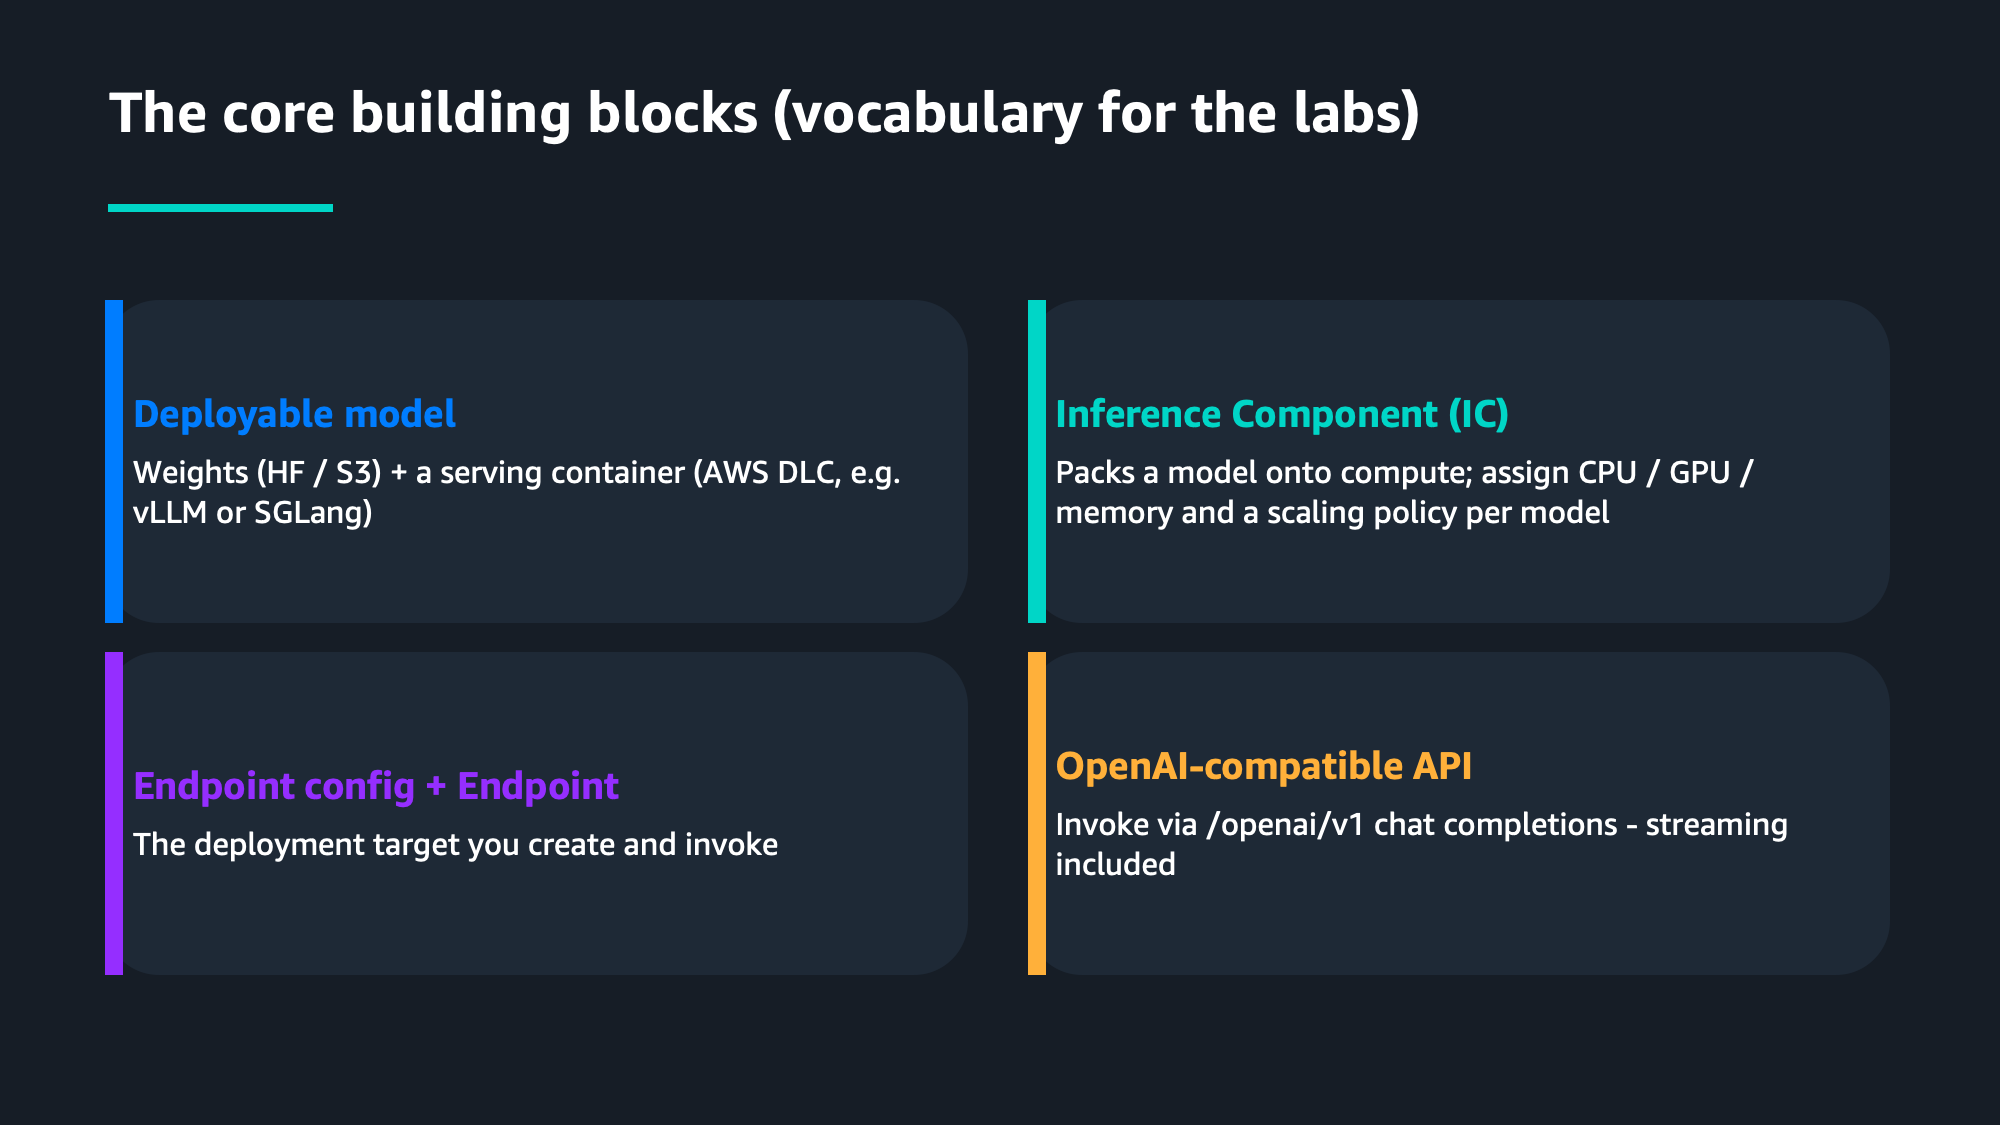

## Deployment

We deploy the model using SageMaker's inference-component workflow:

1. **Create the SageMaker model** – Registers a deployable model definition containing the vLLM container image, environment variables, and IAM execution role. This step defines how the model will run but does not provision compute resources.

2. **Create the endpoint configuration** – Defines the hosting infrastructure. Here, the production variant uses one GPU-instance and a GPU-optimized SageMaker inference AMI. Because we use an inference component, the model is attached separately rather than specified directly in the production variant.

3. **Create the endpoint** – Provisions the instance described by the endpoint configuration and creates the HTTPS endpoint. We wait until its status becomes `InService` before deploying the model.

4. **Create the inference component** – Deploys the model onto the endpoint and specifies how it uses the available resources. Inference components decouple models from endpoint infrastructure, allowing models to be added, removed, or updated independently.

### Step 1: Create the SageMaker models

We register two models that use the same container image and differ only in their environment variables. This step doesn't start any compute.

In [8]:
_ = sm.create_model(
    ModelName=model_name,
    ExecutionRoleArn=role,
    PrimaryContainer={
        "Image": inference_image,
        "Environment": env,
    },
)

In [9]:
_ = sm.create_model(
    ModelName=model_name_spd,
    ExecutionRoleArn=role,
    PrimaryContainer={
        "Image": inference_image,
        "Environment": env_spd,
    },
)

### Steps 2-3: Create the endpoint configuration and endpoint

The endpoint configuration defines the instance type and count, and the inference AMI. Creating the endpoint provisions the instance, which takes about 5-10 minutes. The cell waits until the endpoint is `InService`.

In [ ]:
_ = sm.create_endpoint_config(
    EndpointConfigName=endpoint_config_name,
    ExecutionRoleArn=role,
    ProductionVariants=[
        {
            "VariantName": variant_name,
            "InstanceType": instance["type"],
            "InitialInstanceCount": 1,
            "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
            "InferenceAmiVersion": "al2023-ami-sagemaker-inference-gpu-4-1",
        },
    ],
)

_ = sm.create_endpoint(EndpointName=endpoint_name,
                       EndpointConfigName=endpoint_config_name)

_ = wait_for_endpoint(endpoint_name)

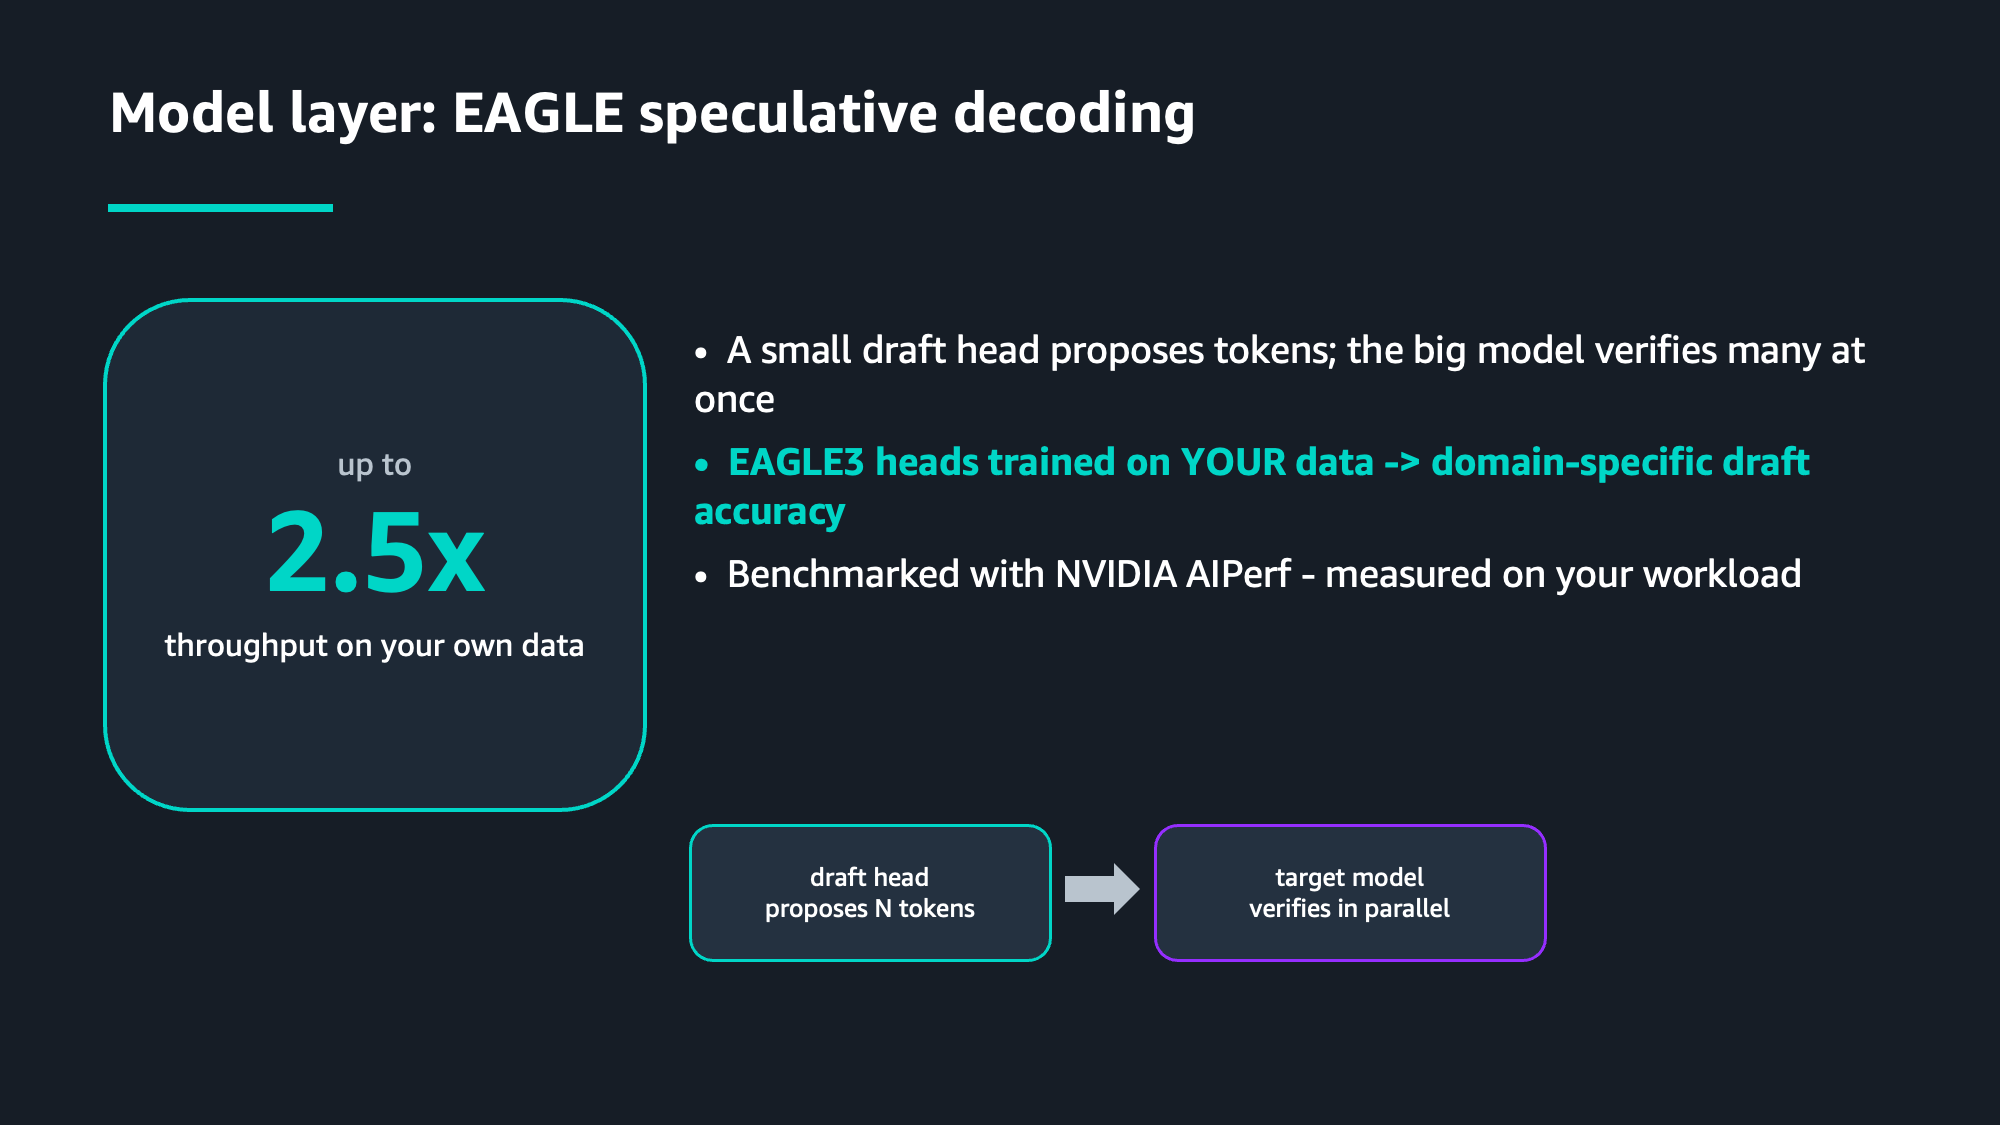

### Step 4: Create the inference components

Each inference component places one copy of a model on the endpoint and reserves accelerators for it. `NumberOfAcceleratorDevicesRequired: 1` matches `SM_VLLM_TENSOR_PARALLEL_SIZE: 1`, so each copy gets the two GPUs it shards across. When the inference component starts, the container downloads the model from the Hugging Face Hub, so startup takes about 10 minutes.

In [11]:
ic_name = f"ic-{model_name}"

min_memory_required_in_mb = 1024
number_of_accelerators = 1

_ = sm.create_inference_component(
    InferenceComponentName=ic_name,
    EndpointName=endpoint_name,
    VariantName=variant_name,
    Specification={
        "ModelName": model_name,
        "StartupParameters": {
            "ModelDataDownloadTimeoutInSeconds": timeout,
            "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
        },
        "ComputeResourceRequirements": {
            "MinMemoryRequiredInMb": min_memory_required_in_mb,
            "NumberOfAcceleratorDevicesRequired": number_of_accelerators,
        },

    },
    RuntimeConfig={
        "CopyCount": 1,
    },
)

ic2_name = f"ic-{model_name_spd}"

_ = sm.create_inference_component(
    InferenceComponentName=ic2_name,
    EndpointName=endpoint_name,
    VariantName=variant_name,
    Specification={
        "ModelName": model_name_spd,
        "StartupParameters": {
            "ModelDataDownloadTimeoutInSeconds": timeout,
            "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
        },
        "ComputeResourceRequirements": {
            "MinMemoryRequiredInMb": min_memory_required_in_mb,
            "NumberOfAcceleratorDevicesRequired": number_of_accelerators,
        },

    },
    RuntimeConfig={
        "CopyCount": 1,
    },
)


In [ ]:
_ = wait_for_ic(ic_name)
_ = wait_for_ic(ic2_name)

## Inference example

Before benchmarking, send one request to check that the model responds. The request uses the OpenAI chat completions format. Because we set the Qwen3 reasoning parser, the response separates the model's reasoning from its final answer, and the helper shows both. `InferenceComponentName` selects which copy serves the request.

In [13]:
#
# Helper function
#
def invoke_endpoint(payload, endpoint_name, inference_component, reasoning_tag="reasoning"):
    start_time = time.time()
    res = sm_runtime.invoke_endpoint(EndpointName=endpoint_name,
                                     InferenceComponentName=inference_component,
                                     Body=json.dumps(payload),
                                     ContentType="application/json")
    response = json.loads(res["Body"].read().decode("utf8"))
    end_time = time.time()

    print(f"✅ Response time: {end_time-start_time:.2f}s\n")

    output = ""
    reasoning = response["choices"][0]["message"].get(reasoning_tag, None)
    if reasoning:
        output += f"### Reasoning:\n---\n{reasoning}\n\n"

    content = response["choices"][0]["message"].get("content", None)
    if content:
        output += f"### Content:\n---\n{content}\n\n---"

    display(Markdown(output))

    return response

In [14]:
payload={
    "messages": [
        {"role": "user", "content": "Who are you?"}
    ],
}
_ = invoke_endpoint(payload, endpoint_name, ic_name)

✅ Response time: 3.03s



### Content:
---
Okay, the user is asking, "Who are you?" This is a pretty straightforward question. I know I'm Qwen3.5, the latest large language model developed by Tongyi Lab. Let me check my knowledge cuts-off and capabilities to make sure I provide accurate info. Wait, the user might just want a simple introduction. I should stay positive and friendly. Maybe briefly mention my key features like language support, reasoning capabilities, and multilingual support, but not too technical. They might just want to know my identity. Also, since I'm the Qwen3.5 version, I should mention that. Oh, and maybe note that I have the following capabilities: robust architectural efficiency, enhanced language foundation, and intelligent visual analysis. But keep it concise and natural. Make sure there are no false claims. Alright, structure the response clearly.
</think>

I'm **Qwen3.5**, the latest large language model developed by **Tongyi Lab**. I'm equipped with robust reasoning capabilities, advanced natural language understanding, multilingual support (over 100 languages), and refined visual analysis for complex tasks. How can I assist you today? 😊

---

Try the same request against the speculative decoding copy by replacing `ic_name` with `ic2_name`. The answer is equivalent, because speculative decoding doesn't change the output.

## Benchmarking with SageMaker generative AI inference recommender

This section uses the benchmarking capability of SageMaker GenAI Inference Recommender to measure the performance of the deployed endpoint. It runs a benchmark against the existing deployment only—it does not create a recommendation job or evaluate alternative deployment configurations.

1. **Define the workload** – Create a reusable workload configuration for inference recommender using the OpenAI-compatible API. Streaming enables token-level measurements, while a warm-up helps stabilize the model before measurement.

2. **Run the benchmark** – Start an AI benchmark job targeting the endpoint and its inference component. The IAM role allows the benchmarking service to invoke the endpoint and write the resulting artifacts to the configured Amazon S3 location.

3. **Monitor and review the results** – Poll the job until it completes. The results include request latency percentiles, request throughput, time to first token (TTFT), inter-token latency (ITL), and output-token throughput.

4. **Clean up benchmark resources** – Delete the benchmark job and workload configuration after the results have been written to Amazon S3.

The same workload should be used for both the baseline and speculative-decoding deployments so their performance can be compared consistently.

Set the S3 location where the benchmark jobs write their results. Replace it with a bucket in your account, for example `s3://sagemaker-<region>-<account-id>/benchmark-output/`.

### Define the workload

The workload configuration describes the synthetic traffic:

- ~256 input tokens and ~128 output tokens per request. `ignore_eos` forces the full output length, so every request does the same amount of work.
- Concurrency levels 1, 2, 4 and 8, with 20 requests at each level. This shows how latency and throughput change as load grows.
- Streaming, so AIPerf can measure time to first token and inter-token latency.
- A 20-second warm-up before measurement.

We create one configuration and reuse it for both benchmark jobs.

In [ ]:
config_name = f"bench-cfg-{endpoint_name}"

workload_spec = {
    "benchmark": {"type": "aiperf"},
    "parameters": {
        "prompt_input_tokens_mean": 256,
        "prompt_input_tokens_stddev": 2,
        "output_tokens_mean": 128,
        "output_tokens_stddev": 2,
        "extra_inputs": "ignore_eos:true",
        "concurrency": [1, 2, 4, 8],
        "request_count": 20,
        "streaming": True,
        "warmup_duration": 20,
    },
    "tooling": {"api_standard": "openai"},
}

response = sm.create_ai_workload_config(
    AIWorkloadConfigName=config_name,
    AIWorkloadConfigs={
        "WorkloadSpec": {"Inline": json.dumps(workload_spec)}
    },
)

print(response["AIWorkloadConfigArn"])

### Run benchmarking job against Inference Component with base model

In [ ]:
job_name = f"bench-job-{ic_name}"
output_s3_location = f"s3://{bucket}/benchmark-output/"

job_response = sm.create_ai_benchmark_job(
    AIBenchmarkJobName=job_name,
    BenchmarkTarget={
        "Endpoint": {
            "Identifier": endpoint_name,
            "InferenceComponents": [  # optional, for IC-endpoints
                {"Identifier": ic_name},
            ]
        }
    },
    OutputConfig={
        "S3OutputLocation": output_s3_location
    },
    AIWorkloadConfigIdentifier=config_name,
    RoleArn=role,
)

print(job_response["AIBenchmarkJobArn"])

### Run benchmarking job against Inference Component with speculative decoding enabled

Each job targets a different inference component, so both run at the same time without competing for GPUs.

In [ ]:
job_name_spd = f"bench-job-{ic2_name}"

job_response = sm.create_ai_benchmark_job(
    AIBenchmarkJobName=job_name_spd,
    BenchmarkTarget={
        "Endpoint": {
            "Identifier": endpoint_name,
            "InferenceComponents": [  # optional, for IC-endpoints
                {"Identifier": ic2_name},
            ]
        }
    },
    OutputConfig={
        "S3OutputLocation": output_s3_location
    },
    AIWorkloadConfigIdentifier=config_name,
    RoleArn=role,
)

print(job_response["AIBenchmarkJobArn"])

### Wait for the results

The next two cells poll each job until it finishes, which takes about 10-15 minutes. Each job writes an `output.tar.gz` archive with the AIPerf results to S3, and the cells save its path for the analysis below.

In [ ]:
while True:
    response = sm.describe_ai_benchmark_job(AIBenchmarkJobName=job_name)
    status = response["AIBenchmarkJobStatus"]
    print(f"Status: {status}")

    if status in ("Completed", "Failed", "Stopped"):
        break

    time.sleep(30)

if status == "Completed":
    print("Benchmark completed successfully!")
    s3_uri_base = f"{response['OutputConfig']['S3OutputLocation']}output/output.tar.gz"
    print(f"Results at: {s3_uri_base}")
elif status == "Failed":
    print(f"Benchmark failed: {response.get('FailureReason', 'unknown')}")

In [ ]:
while True:
    response = sm.describe_ai_benchmark_job(AIBenchmarkJobName=job_name_spd)
    status = response["AIBenchmarkJobStatus"]
    print(f"Status: {status}")

    if status in ("Completed", "Failed", "Stopped"):
        break

    time.sleep(30)

if status == "Completed":
    print("Benchmark completed successfully!")
    s3_uri_spd = f"{response['OutputConfig']['S3OutputLocation']}output/output.tar.gz"
    print(f"Results at: {s3_uri_spd}")
elif status == "Failed":
    print(f"Benchmark failed: {response.get('FailureReason', 'unknown')}")

## Speculative decoding performance analysis

The archive contains a sweep summary with one row per concurrency level. We load two metrics:

- `request_latency_mean`: average time from sending a request to receiving the last token (ms)
- `output_token_throughput_mean`: output tokens per second across all concurrent requests

In [20]:
from pathlib import PurePosixPath
from urllib.parse import urlparse
import tarfile
import tempfile

import boto3
import pandas as pd

In [21]:
def load_perf_sweep(s3_uri: str, s3_client=None) -> pd.DataFrame:
    """Download an s3://bucket/key/output.tar.gz and return its sweep metrics."""
    location = urlparse(s3_uri)
    bucket = location.netloc
    key = location.path.lstrip("/")
    if location.scheme != "s3" or not bucket or not key:
        raise ValueError("Provide an S3 object URI, e.g. s3://bucket/path/output.tar.gz")

    columns = ["concurrency", "request_latency_mean", "output_token_throughput_mean"]
    target = ("sweep_aggregate", "profile_export_aiperf_sweep.csv")
    if s3_client is None:
        s3_client = boto3.client("s3")

    # Keep the downloaded archive on temporary storage and read only the CSV.
    with tempfile.TemporaryFile() as downloaded:
        s3_client.download_fileobj(bucket, key, downloaded)
        downloaded.seek(0)
        with tarfile.open(fileobj=downloaded, mode="r:gz") as archive:
            for member in archive:
                if member.isfile() and PurePosixPath(member.name).parts[-2:] == target:
                    csv_file = archive.extractfile(member)
                    if csv_file is not None:
                        with csv_file:
                            return pd.read_csv(csv_file, usecols=columns, nrows=4)[columns]

    raise FileNotFoundError(f"{'/'.join(target)} was not found in {s3_uri}")

In [22]:
df = load_perf_sweep(s3_uri_base)
print(df.to_string(index=False))

 concurrency  request_latency_mean  output_token_throughput_mean
           1               1628.67                         78.82
           2               1693.85                        151.16
           4               1787.96                        284.25
           8               1948.83                        449.28


In [23]:
df_spd = load_perf_sweep(s3_uri_spd)
print(df_spd.to_string(index=False))

 concurrency  request_latency_mean  output_token_throughput_mean
           1                995.80                        128.91
           2               1076.81                        233.25
           4               1176.65                        418.00
           8               1403.22                        639.70


### Plot the results

How to read the charts:

- At low concurrency the GPU has spare compute, so speculative decoding should show lower latency and higher throughput.
- As concurrency grows, batches get larger and the GPU gets busier, so the gap usually shrinks.

Choose the configuration based on where your expected traffic sits on these curves.

In [24]:
import matplotlib.pyplot as plt
import pandas as pd


def plot_sweep_comparison(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
    labels=("DF 1", "DF 2"),
):
    """Return a figure and two axes comparing the supplied sweep results."""
    metrics = (
        ("request_latency_mean", "Mean request latency"),
        ("output_token_throughput_mean", "Mean output token throughput"),
    )
    required = {"concurrency", *(column for column, _ in metrics)}
    if len(labels) != 2:
        raise ValueError("Provide exactly two labels, one for each DataFrame.")

    for label, df in zip(labels, (df1, df2)):
        missing = required - set(df.columns)
        if missing:
            raise ValueError(f"{label} is missing columns: {', '.join(sorted(missing))}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, layout="constrained")

    for df, label, color, marker in zip(
        (df1, df2), labels, ("tab:blue", "tab:orange"), ("o", "s")
    ):
        ordered = df.sort_values("concurrency")
        for ax, (column, _) in zip(axes, metrics):
            ax.plot(
                ordered["concurrency"],
                ordered[column],
                label=label,
                color=color,
                marker=marker,
                linewidth=2,
            )

    for ax, (_, title) in zip(axes, metrics):
        ax.set_title(title)
        ax.set_xlabel("Concurrency")
        ax.set_ylabel(title)
        ax.grid(True, alpha=0.3)
        ax.legend()

    return fig, axes

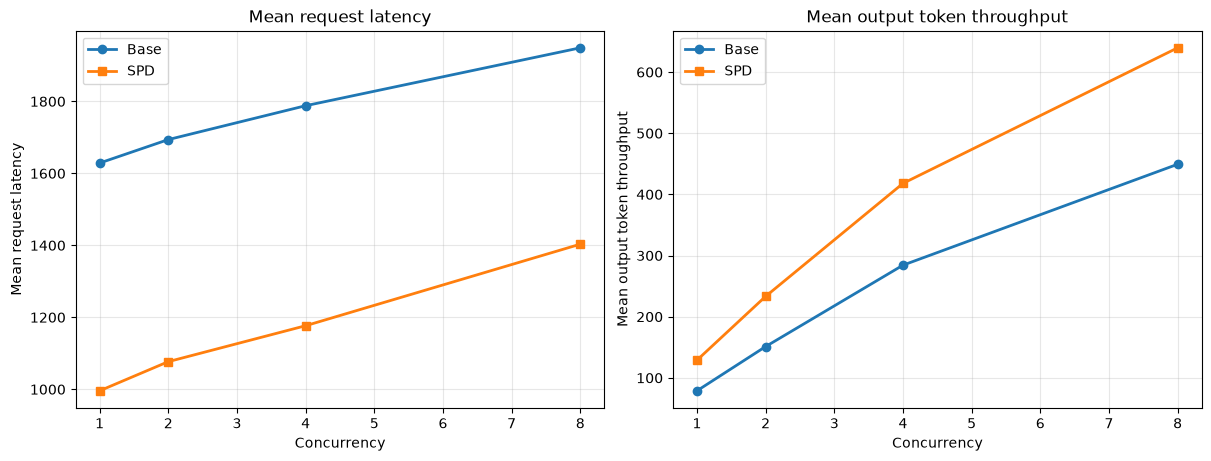

In [25]:
fig, axes = plot_sweep_comparison(
    df,
    df_spd,
    labels=("Base", "SPD"),
)

plt.show()

### CloudWatch dashboard

**You can also find endpoint performance metrics in SageMaker CloudWatch Insights dashboard**

## Cleanup

Delete the benchmark jobs, the workload configuration, both inference components, the endpoint and the models to stop charges. Benchmark results stay in S3. Set `CLEANUP = False` if you want to keep the endpoint running.

In [26]:
CLEANUP = True

In [27]:
if CLEANUP:
    _ = sm.delete_ai_benchmark_job(AIBenchmarkJobName=job_name)
    _ = sm.delete_ai_benchmark_job(AIBenchmarkJobName=job_name_spd)
    _ = sm.delete_ai_workload_config(AIWorkloadConfigName=config_name)

In [28]:
if CLEANUP:
    _ = sm.delete_inference_component(InferenceComponentName=ic_name)
    _ = sm.delete_inference_component(InferenceComponentName=ic2_name)

In [29]:
if CLEANUP:
    _ = sm.delete_endpoint(EndpointName=endpoint_name)
    _ = sm.delete_endpoint_config(EndpointConfigName=endpoint_config_name)
    _ = sm.delete_model(ModelName=model_name)
    _ = sm.delete_model(ModelName=model_name_spd)